# Stage 2 — DeepXDE: forward and inverse problems

**Vamsi Gudipati**

I solve steady heat conduction on a square with DeepXDE and check it against a finite-difference solution, then turn it into an inverse problem: recover the conductivity from 12 sensor readings, look at sensor placement and noise, recover a viscosity from a velocity profile (where only a ratio is identifiable), show a case the data cannot identify at all, and finish with a Stefan solidification front. I added a training animation and repeated every trained result with three seeds. All trainings run on the CPU: DeepXDE makes the Apple GPU the default device on import, and it is slower here, so I set the CPU right after the import. `test_pinn_inverse.py` next to this notebook is the hand-written inverse PINN of Stage 3 as a plain script.

Portfolio page: https://vamsigudipati.github.io/physics-informed-pinn-deeponet.html


In [1]:
# Where this notebook writes its outputs (paths relative to notebooks/)
from pathlib import Path
STAGE = "02_deepxde_forward_and_inverse"
RESULTS_DIR = Path("../results") / STAGE
EXERCISES_DIR = RESULTS_DIR / "exercises"
MODELS_DIR = Path("../models") / STAGE
ANIM_DIR = Path("../animations")
ANIM_PREFIX = "02_"
for _d in (RESULTS_DIR, EXERCISES_DIR, MODELS_DIR, ANIM_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Stage 2: DeepXDE and the Inverse Problem

Stage 1 built a PINN by hand. Here we let **DeepXDE** do the heavy lifting and turn the question around.

- **Forward problem:** parameters known  →  find the field.
- **Inverse problem:** a few sensor readings known  →  find the parameter.

Inverse problems are where PINNs earn their place in industry: identifying a conductivity, a viscosity, or a heat-transfer coefficient from sparse measurements.

In [2]:
# Device report: which devices this kernel sees
import os, platform, torch
print("DDE_BACKEND =", os.environ.get("DDE_BACKEND"), "| PyTorch", torch.__version__, "| Python", platform.python_version())
print("MPS available:", torch.backends.mps.is_available())

DDE_BACKEND = pytorch | PyTorch 2.14.1 | Python 3.12.14
MPS available: True


### Running this notebook

Run the cells top to bottom. A few cells train small networks and take some seconds on a CPU, they are flagged in a comment. Nothing here needs a GPU.

## Setup

In [3]:
# DeepXDE lets us pick its numerical backend. We use PyTorch, and this choice
# must be made BEFORE importing deepxde.
import os
os.environ["DDE_BACKEND"] = "pytorch"

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import deepxde as dde
import torch
torch.set_default_device("cpu")         # DeepXDE 1.15 makes the Apple GPU (MPS) the default device on import; it is slower here (4.4 vs 1.9 ms per Adam iteration), so I keep the CPU

print("deepxde", dde.__version__, "| backend", dde.backend.backend_name)
print("torch  ", torch.__version__, "| cuda", torch.cuda.is_available())

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


deepxde 1.15.0 | backend pytorch
torch   2.14.1 | cuda False


In [4]:
# One seed drives numpy and torch, so every run is reproducible.
dde.config.set_random_seed(0)
np.random.seed(0)

# Speed guardrail. By default DeepXDE runs L-BFGS for up to 15000 iterations,
# which is painfully slow on a CPU. 1000 is plenty for the small problems here.
dde.optimizers.set_LBFGS_options(maxiter=1000)

In [5]:
# Figure defaults.
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = False

# Colorblind-safe line colors (Okabe-Ito) and perceptual colormaps for fields.
OKABE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442"]
CMAP_T   = "inferno"   # temperature
CMAP_V   = "viridis"   # velocity
CMAP_ERR = "cividis"   # error

In [6]:
# Read a DeepXDE trainable variable as a plain Python float.
def read_var(v):
    return float(v.item())


# A small callback that records a variable's value after each epoch,
# so we can plot how it converges during training.
class TrackVar(dde.callbacks.Callback):
    def __init__(self, var):
        super().__init__()
        self.var = var
        self.history = []

    def on_epoch_end(self):
        self.history.append(read_var(self.var))

## DeepXDE in five objects

Every cell below is built from the same five pieces:

1. **Geometry** : the domain (`dde.geometry.*`).
2. **Residual** : the physics, written as "this should be zero".
3. **Conditions** : boundary conditions and sensor data (`dde.icbc.*`).
4. **Data** : where the residual and conditions are sampled (`dde.data.PDE`).
5. **Model** : the network plus the training loop (`dde.Model`).

Keep these straight and every cell reads the same way.

# Part A : The forward problem (recap)

Steady heat conduction on the unit square, uniform source, cold edges:

$$-k\,(T_{xx} + T_{yy}) = Q, \qquad T = 0 \text{ on the boundary.}$$

We first solve it with a classic finite-difference scheme (our **baseline** and **ground truth**), then reproduce it with a PINN.

In [7]:
# Finite-difference reference for  -k*(T_xx + T_yy) = Q  on [0,1]^2,
# with T = 0 on all edges. Returns the temperature on an (n x n) grid.
def fd_poisson(k, Q, n=61):
    h = 1.0 / (n - 1)
    N = n - 2                       # interior points per axis

    # 1D second-derivative stencil, then the 2D Laplacian built from it.
    e  = np.ones(N)
    T1 = sp.diags([e[:-1], -2 * e, e[:-1]], [-1, 0, 1])
    I  = sp.identity(N)
    L  = (sp.kron(I, T1) + sp.kron(T1, I)) / h**2

    # Right-hand side from  lap(T) = -Q/k.
    b = np.full(N * N, -Q / k)
    u = spla.spsolve(L.tocsr(), b)

    # Put the interior solution back into the full grid (edges stay 0).
    T = np.zeros((n, n))
    T[1:-1, 1:-1] = u.reshape(N, N)
    return T

In [8]:
# Ground-truth setup: known conductivity, source, and grid resolution.
k_true, Q = 0.8, 1.0
n_ref = 61

# Solve once, and build a coordinate grid we reuse everywhere for plotting.
T_ref = fd_poisson(k_true, Q, n=n_ref)
xs = np.linspace(0, 1, n_ref)
XX, YY = np.meshgrid(xs, xs)

print("reference grid:", T_ref.shape)
print("peak temperature:", round(T_ref.max(), 4), "(scales like Q/k)")

reference grid: (61, 61)
peak temperature: 0.0921 (scales like Q/k)


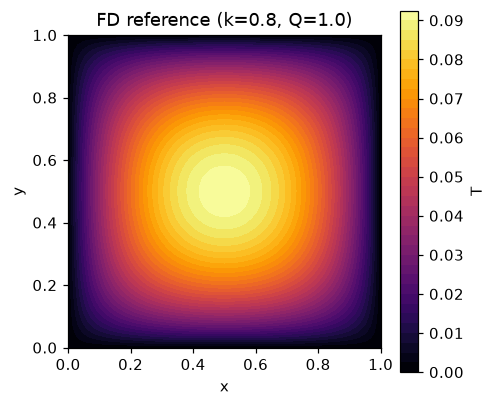

In [9]:
# Look at the reference field.
fig, ax = plt.subplots(figsize=(4.6, 4.0))
im = ax.contourf(XX, YY, T_ref, levels=40, cmap=CMAP_T)
plt.colorbar(im, ax=ax, label="T")

ax.set_title(f"FD reference (k={k_true}, Q={Q})")
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### The forward PINN

Same physics, now solved by a network. The residual returns $-k(T_{xx}+T_{yy}) - Q$, which should be zero everywhere. Watch the five objects appear one by one.

In [10]:
# 1. Geometry: the unit square.
geom = dde.geometry.Rectangle([0, 0], [1, 1])


# 2. Residual: the physics. hessian(T, x, i, j) is the second derivative.
def heat_forward(x, T):
    T_xx = dde.grad.hessian(T, x, i=0, j=0)
    T_yy = dde.grad.hessian(T, x, i=1, j=1)
    return -k_true * (T_xx + T_yy) - Q


# 3. Condition: T = 0 on the whole boundary.
bc = dde.icbc.DirichletBC(geom, lambda x: 0.0, lambda x, on_b: on_b)

In [11]:
# 4. Data: where the residual and BC are sampled during training.
data_fwd = dde.data.PDE(geom, heat_forward, [bc],
                        num_domain=600, num_boundary=120, num_test=400)

# 5. Model: a small network, 2 inputs (x, y) -> 1 output (T).
net_fwd = dde.nn.FNN([2, 32, 32, 32, 1], "tanh", "Glorot uniform")
model_fwd = dde.Model(data_fwd, net_fwd)

# The loss terms come in this order: PDE residual first, then the BC.
print("loss terms, in order: ['PDE residual', 'DirichletBC']")

loss terms, in order: ['PDE residual', 'DirichletBC']


**Training hook.** I give the Adam stage of the forward PINN (`model_fwd.train(iterations=3000, ...)`) two DeepXDE callbacks: `ANIM_CB` stores the field on the 61×61 reference grid and its RMSE against the finite-difference reference every 50 iterations for the training animation (it only evaluates the network), and DeepXDE's `ModelCheckpoint` writes a checkpoint every 500 iterations. The L-BFGS stage is unchanged; the animation's last frame is the final model after it.

In [12]:
from pathlib import Path
EX_CKPT = MODELS_DIR / "checkpoints"; EX_CKPT.mkdir(parents=True, exist_ok=True)
anim_xy = np.column_stack([XX.ravel(), YY.ravel()]).astype(np.float32)
class AnimSnapshots(dde.callbacks.Callback):
    def __init__(self, every=50): super().__init__(); self.every = every; self.snaps = []; self.it = 0
    def snap(self, label=None):
        with torch.no_grad():
            T_ = self.model.net(torch.as_tensor(anim_xy)).detach().cpu().numpy().reshape(n_ref, n_ref)
        self.snaps.append(dict(it=self.it if label is None else label, T=T_, err=float(np.sqrt(np.mean((T_ - T_ref) ** 2)))))
    def on_train_begin(self): self.snap()
    def on_epoch_end(self):
        self.it += 1
        if self.it % self.every == 0: self.snap()
ANIM_CB = AnimSnapshots()
EX_CKPT_CB = dde.callbacks.ModelCheckpoint(str(EX_CKPT / "pinn_forward"), save_better_only=False, period=500)

In [13]:
# Trains the network : about 15-30 s on CPU.
# Two-stage training: Adam to get close, then L-BFGS to polish.
model_fwd.compile("adam", lr=1e-3)
model_fwd.train(iterations=3000, display_every=1000, callbacks=[ANIM_CB, EX_CKPT_CB])  # hook: animation snapshots, checkpoint every 500 iterations

model_fwd.compile("L-BFGS")
losshistory, _ = model_fwd.train()
print("training done")

Compiling model...
'compile' took 0.000191 s



Training model...

Step      Train loss              Test loss               Test metric


0         [9.36e-01, 1.87e-02]    [9.37e-01, 1.87e-02]    []  


1000      [6.99e-04, 7.23e-04]    [4.91e-04, 7.23e-04]    []  


2000      [3.14e-05, 4.07e-04]    [2.08e-05, 4.07e-04]    []  


...

Training model...

Step      Train loss              Test loss               Test metric


3000      [2.46e-05, 3.99e-04]    [1.63e-05, 3.99e-04]    []  


4000      [9.08e-06, 9.46e-06]    [6.63e-06, 9.46e-06]    []  



Best model at step 4000:
  train loss: 1.85e-05
  test loss: 1.61e-05
  test metric: []

'train' took 3.719000 s



training done


In [14]:
# Evaluate the trained network on the same grid as the FD reference.
xy = np.column_stack([XX.ravel(), YY.ravel()])
T_pinn = model_fwd.predict(xy).reshape(n_ref, n_ref)

# Pointwise error against the reference.
err = np.abs(T_pinn - T_ref)
print(f"max |PINN - FD| = {err.max():.5f}   mean = {err.mean():.5f}")

max |PINN - FD| = 0.01093   mean = 0.00136


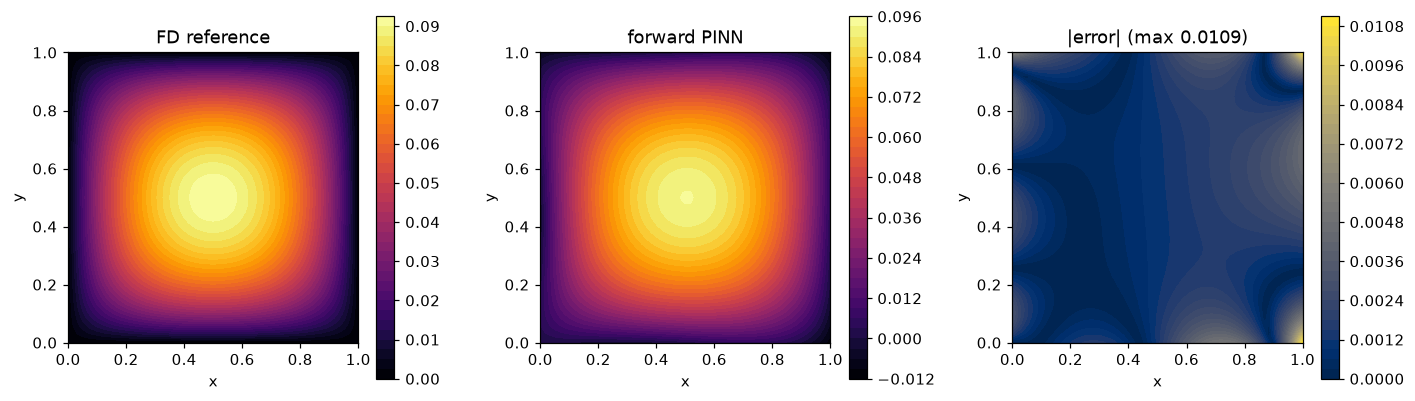

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))

# Reference field.
im0 = axs[0].contourf(XX, YY, T_ref, levels=40, cmap=CMAP_T)
plt.colorbar(im0, ax=axs[0]); axs[0].set_title("FD reference")

# PINN prediction.
im1 = axs[1].contourf(XX, YY, T_pinn, levels=40, cmap=CMAP_T)
plt.colorbar(im1, ax=axs[1]); axs[1].set_title("forward PINN")

# Error map.
im2 = axs[2].contourf(XX, YY, err, levels=40, cmap=CMAP_ERR)
plt.colorbar(im2, ax=axs[2]); axs[2].set_title(f"|error| (max {err.max():.4f})")

for a in axs:
    a.set_xlabel("x"); a.set_ylabel("y"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

# Part B — The inverse problem

## Example 1 — Recover an unknown conductivity

Now $k$ is unknown. You have a new material and a few thermocouples in a sample under a known load. Can you recover $k$ from those sparse readings?

The trick: make $k$ a **trainable variable** and let the PDE plus the sensor data pull it to the right value.

In [16]:
# Read the reference field at arbitrary (x, y) points by bilinear interpolation.
# Sensors rarely sit exactly on grid nodes, so we blend the four nearest nodes.
def sample_field(T, xq, yq):
    n = T.shape[0]

    # Map coordinates in [0,1] to (fractional) grid indices.
    gx = np.clip(xq * (n - 1), 0, n - 1 - 1e-9)
    gy = np.clip(yq * (n - 1), 0, n - 1 - 1e-9)

    # Integer corner indices, and the fractional offset inside each cell.
    x0 = np.floor(gx).astype(int); fx = gx - x0
    y0 = np.floor(gy).astype(int); fy = gy - y0

    # Blend along x on the bottom and top edges, then blend along y.
    bottom = T[y0,     x0] * (1 - fx) + T[y0,     x0 + 1] * fx
    top    = T[y0 + 1, x0] * (1 - fx) + T[y0 + 1, x0 + 1] * fx
    return bottom * (1 - fy) + top * fy

In [17]:
# Pretend k is unknown. Place a handful of thermocouples in the sample.
rng = np.random.default_rng(1)
N_sensors = 12

# Random interior positions, away from the cold edges.
sx = rng.uniform(0.1, 0.9, N_sensors)
sy = rng.uniform(0.1, 0.9, N_sensors)
obs_xy = np.column_stack([sx, sy])

# The "measurements": the reference field read at those positions.
obs_T = sample_field(T_ref, sx, sy).reshape(-1, 1)

for i in range(N_sensors):
    print(f"  #{i:2d}  (x={sx[i]:.2f}, y={sy[i]:.2f})  ->  T = {obs_T[i, 0]:.4f}")

  # 0  (x=0.51, y=0.36)  ->  T = 0.0861
  # 1  (x=0.86, y=0.73)  ->  T = 0.0398
  # 2  (x=0.22, y=0.34)  ->  T = 0.0601
  # 3  (x=0.86, y=0.46)  ->  T = 0.0478
  # 4  (x=0.35, y=0.21)  ->  T = 0.0590
  # 5  (x=0.44, y=0.42)  ->  T = 0.0890
  # 6  (x=0.76, y=0.26)  ->  T = 0.0565
  # 7  (x=0.43, y=0.31)  ->  T = 0.0790
  # 8  (x=0.54, y=0.70)  ->  T = 0.0787
  # 9  (x=0.12, y=0.32)  ->  T = 0.0389
  #10  (x=0.70, y=0.49)  ->  T = 0.0788
  #11  (x=0.53, y=0.88)  ->  T = 0.0408


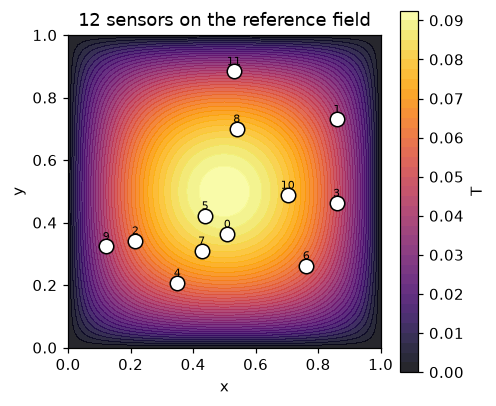

In [18]:
fig, ax = plt.subplots(figsize=(4.6, 4.0))
im = ax.contourf(XX, YY, T_ref, levels=40, cmap=CMAP_T, alpha=0.85)
plt.colorbar(im, ax=ax, label="T")

# Mark and number each sensor.
ax.scatter(sx, sy, c="white", edgecolors="black", s=90, zorder=5)
for i in range(N_sensors):
    ax.text(sx[i], sy[i] + 0.02, str(i), ha="center", fontsize=7)

ax.set_title(f"{N_sensors} sensors on the reference field")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### The inverse solve

One reusable function. The placement and noise studies below all call it. It returns the recovered $k$, its trajectory during training, and the trained model.

In [19]:
# Reusable inverse solve for k. It makes k a trainable variable, adds the
# sensor readings as data, trains, and returns the recovered k.
def inverse_k(obs_xy, obs_T, Q=1.0, bc_value=0.0, k_init=1.5,
              adam_iters=3000, use_lbfgs=True, seed=0):
    dde.config.set_random_seed(seed)

    # The unknown we want to recover, starting at a deliberately wrong guess.
    k_var = dde.Variable(k_init)

    # Same physics as the forward problem, but k is now the variable k_var.
    def pde(x, T):
        T_xx = dde.grad.hessian(T, x, i=0, j=0)
        T_yy = dde.grad.hessian(T, x, i=1, j=1)
        return -k_var * (T_xx + T_yy) - Q

    # Two constraints: the boundary condition and the sensor measurements.
    bc  = dde.icbc.DirichletBC(geom, lambda x: bc_value, lambda x, on: on)
    obs = dde.icbc.PointSetBC(obs_xy, obs_T, component=0)

    # anchors keeps the sensor points in the training set.
    data = dde.data.PDE(geom, pde, [bc, obs],
                        num_domain=500, num_boundary=100, anchors=obs_xy)
    net   = dde.nn.FNN([2, 32, 32, 32, 1], "tanh", "Glorot uniform")
    model = dde.Model(data, net)

    # Record k at every epoch, so we can watch it converge.
    track = TrackVar(k_var)

    # Adam first; k is passed as an extra trainable variable.
    model.compile("adam", lr=1e-3, external_trainable_variables=[k_var])
    model.train(iterations=adam_iters, display_every=1000000, callbacks=[track])

    # Optional L-BFGS polish.
    if use_lbfgs:
        model.compile("L-BFGS", external_trainable_variables=[k_var])
        model.train(display_every=1000000)

    return read_var(k_var), track.history, model

In [20]:
# Recover k from the 12 sensors. Trains a network — about 15-30 s on CPU.
k_rec, k_hist, model_inv = inverse_k(obs_xy, obs_T)

print("=" * 40)
print(f"  true k         : {k_true:.4f}")
print(f"  initial guess  : 1.5000")
print(f"  recovered k    : {k_rec:.4f}")
print(f"  relative error : {abs(k_rec - k_true) / k_true * 100:.2f} %")
print("=" * 40)

Compiling model...
'compile' took 0.000141 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.84e-01, 1.89e-02, 2.92e-03]    [8.84e-01, 1.89e-02, 2.92e-03]    []  


3000      [2.89e-05, 2.73e-04, 2.08e-04]    [2.89e-05, 2.73e-04, 2.08e-04]    []  



Best model at step 3000:
  train loss: 5.10e-04
  test loss: 5.10e-04
  test metric: []

'train' took 6.153696 s



...

Training model...

Step      Train loss                        Test loss                         Test metric


3000      [2.89e-05, 2.73e-04, 2.08e-04]    [2.89e-05, 2.73e-04, 2.08e-04]    []  


4000      [2.83e-05, 2.75e-05, 1.65e-06]    [2.83e-05, 2.75e-05, 1.65e-06]    []  



Best model at step 4000:
  train loss: 5.75e-05
  test loss: 5.75e-05
  test metric: []

'train' took 3.682972 s



  true k         : 0.8000
  initial guess  : 1.5000
  recovered k    : 0.8466
  relative error : 5.82 %


In [21]:
# Field reconstructed by the inverse PINN, and its error vs the reference.
T_inv = model_inv.predict(xy).reshape(n_ref, n_ref)
err_inv = np.abs(T_inv - T_ref)

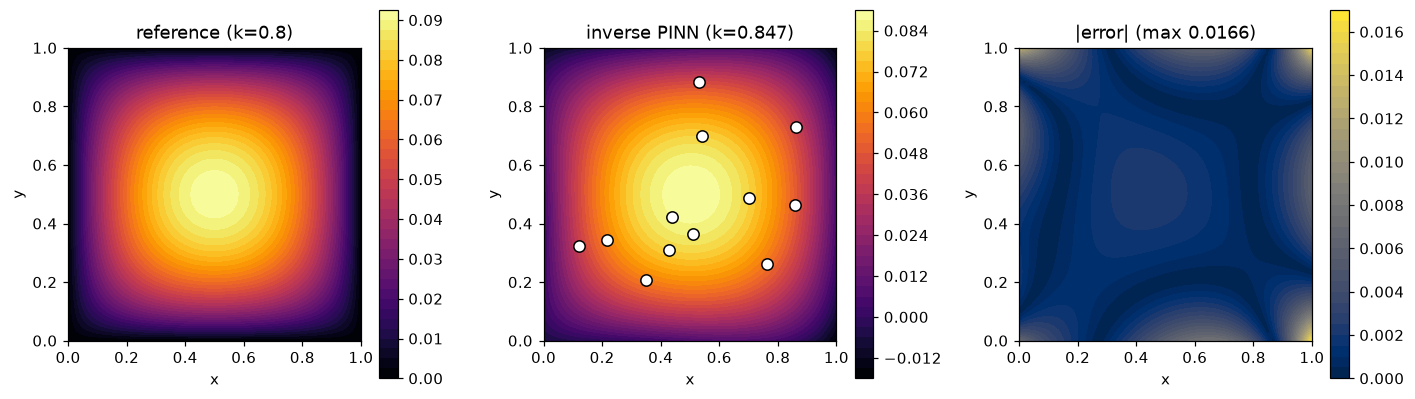

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))

# Reference field.
im0 = axs[0].contourf(XX, YY, T_ref, levels=40, cmap=CMAP_T)
plt.colorbar(im0, ax=axs[0]); axs[0].set_title(f"reference (k={k_true})")

# Field recovered by the inverse PINN, with sensors marked.
im1 = axs[1].contourf(XX, YY, T_inv, levels=40, cmap=CMAP_T)
plt.colorbar(im1, ax=axs[1])
axs[1].scatter(sx, sy, c="white", edgecolors="black", s=55, zorder=5)
axs[1].set_title(f"inverse PINN (k={k_rec:.3f})")

# Error map.
im2 = axs[2].contourf(XX, YY, err_inv, levels=40, cmap=CMAP_ERR)
plt.colorbar(im2, ax=axs[2]); axs[2].set_title(f"|error| (max {err_inv.max():.4f})")

for a in axs:
    a.set_xlabel("x"); a.set_ylabel("y"); a.set_aspect("equal")
plt.tight_layout(); plt.show()

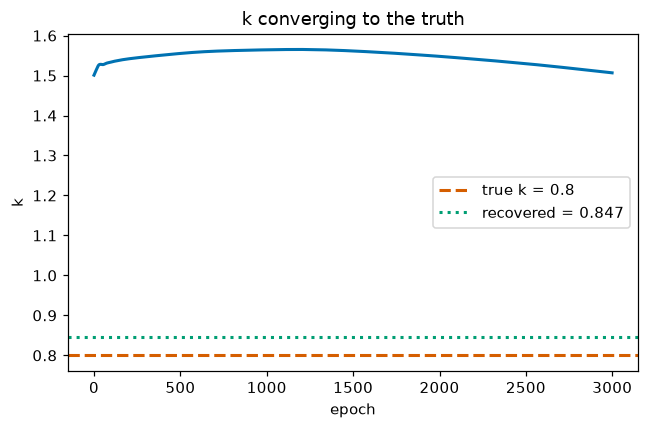

In [23]:
# How the unknown k converged toward the truth during Adam.
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_hist, color=OKABE[0], lw=2)
ax.axhline(k_true, color=OKABE[3], ls="--", lw=2, label=f"true k = {k_true}")
ax.axhline(k_rec,  color=OKABE[2], ls=":",  lw=2, label=f"recovered = {k_rec:.3f}")

ax.set_xlabel("epoch"); ax.set_ylabel("k")
ax.set_title("k converging to the truth")
ax.legend(); plt.tight_layout(); plt.show()

### Where you put the sensors matters

The field is largest in the middle and near zero along the cold edges. A sensor where the temperature is almost flat tells you very little about $k$. Let's compare three layouts.

In [24]:
# Three sensor layouts to compare.
layouts = {}

# (1) Spread across the interior, where the field is informative.
r = np.random.default_rng(2)
layouts["spread interior"] = np.column_stack([r.uniform(0.15, 0.85, 12),
                                              r.uniform(0.15, 0.85, 12)])

# (2) Hugging the cold edges, where the field is tiny and nearly flat.
r = np.random.default_rng(3)
edge = np.concatenate([r.uniform(0.02, 0.12, 6), r.uniform(0.88, 0.98, 6)])
layouts["near cold edge"] = np.column_stack([edge, r.uniform(0.1, 0.9, 12)])

# (3) Only a few points, clustered near the hot centre.
r = np.random.default_rng(4)
layouts["few, central"] = np.column_stack([r.uniform(0.4, 0.6, 4),
                                           r.uniform(0.4, 0.6, 4)])

In [25]:
# Recover k for each layout. We skip L-BFGS here: Adam alone already pins the
# scalar k, and skipping it keeps three solves fast.
place_results = {}
for name, pts in layouts.items():
    oT = sample_field(T_ref, pts[:, 0], pts[:, 1]).reshape(-1, 1)
    kk, _, _ = inverse_k(pts, oT, adam_iters=2000, use_lbfgs=False)
    place_results[name] = kk

    err_pct = abs(kk - k_true) / k_true * 100
    print(f"{name:16s} ({len(pts):2d} pts) -> k = {kk:.4f}  (err {err_pct:.1f}%)")

Compiling model...
'compile' took 0.000166 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.83e-01, 1.89e-02, 3.20e-03]    [8.83e-01, 1.89e-02, 3.20e-03]    []  


2000      [3.68e-05, 3.62e-04, 2.24e-04]    [3.68e-05, 3.62e-04, 2.24e-04]    []  



Best model at step 2000:
  train loss: 6.23e-04
  test loss: 6.23e-04
  test metric: []

'train' took 4.093409 s



...

Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.84e-01, 1.89e-02, 4.96e-05]    [8.84e-01, 1.89e-02, 4.96e-05]    []  


2000      [3.79e-05, 4.78e-04, 3.35e-04]    [3.79e-05, 4.78e-04, 3.35e-04]    []  



Best model at step 2000:
  train loss: 8.51e-04
  test loss: 8.51e-04
  test metric: []

'train' took 4.080639 s



few, central     ( 4 pts) -> k = 1.5107  (err 88.8%)


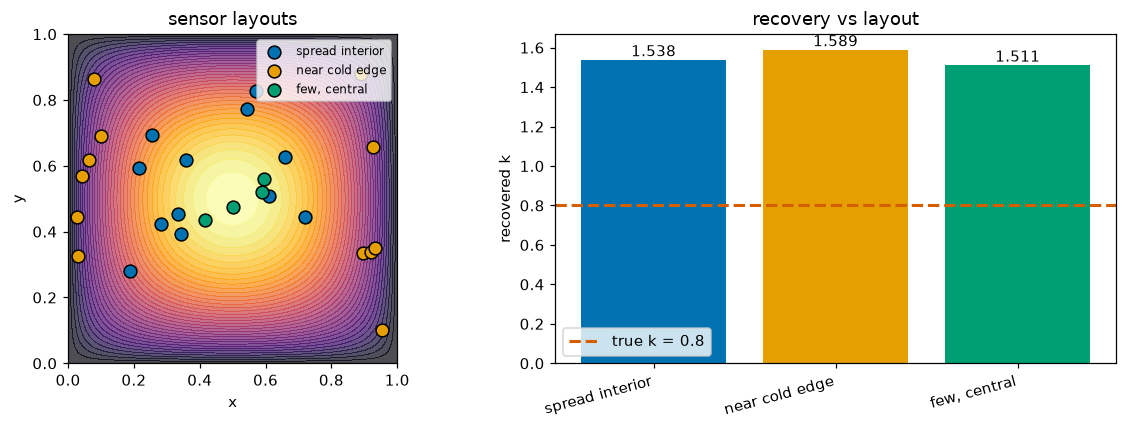

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))

# Left: where the sensors sit for each layout.
axs[0].contourf(XX, YY, T_ref, levels=40, cmap=CMAP_T, alpha=0.7)
for (name, pts), c in zip(layouts.items(), OKABE):
    axs[0].scatter(pts[:, 0], pts[:, 1], s=70, color=c,
                   edgecolors="black", label=name, zorder=5)
axs[0].legend(fontsize=8, loc="upper right")
axs[0].set_title("sensor layouts")
axs[0].set_xlabel("x"); axs[0].set_ylabel("y"); axs[0].set_aspect("equal")

# Right: recovered k for each layout vs the true value.
names = list(place_results.keys())
values = [place_results[n] for n in names]
axs[1].bar(names, values, color=OKABE[:len(names)])
axs[1].axhline(k_true, color=OKABE[3], ls="--", lw=2, label=f"true k = {k_true}")
for i, v in enumerate(values):
    axs[1].text(i, v, f"{v:.3f}", ha="center", va="bottom")
axs[1].set_ylabel("recovered k"); axs[1].set_title("recovery vs layout")
axs[1].legend()
plt.setp(axs[1].get_xticklabels(), rotation=15, ha="right")
plt.tight_layout(); plt.show()

The PDE constraint is strong: even weak layouts stay in the right neighbourhood — that is the point of physics-informed identification. But informative placement gives the cleanest recovery.

### How noise degrades the answer

Real sensors are noisy. We add zero-mean Gaussian noise scaled to the field size and re-identify $k$ at each level — a practical read on your noise budget.

In [27]:
# Add noise (as a fraction of the field max) and re-identify k each time.
# Adam only again, to keep it quick.
Tmax = T_ref.max()
noise_fracs = [0.0, 0.02, 0.05, 0.10]
noise_results = []

for f in noise_fracs:
    ng = np.random.default_rng(100)
    noise = f * Tmax * ng.standard_normal((N_sensors, 1))
    oT = sample_field(T_ref, sx, sy).reshape(-1, 1) + noise

    kk, _, _ = inverse_k(obs_xy, oT, adam_iters=2000, use_lbfgs=False)
    noise_results.append(kk)

    err_pct = abs(kk - k_true) / k_true * 100
    print(f"noise {f*100:4.0f}% of Tmax  ->  k = {kk:.4f}  (err {err_pct:.1f}%)")

Compiling model...
'compile' took 0.000165 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.84e-01, 1.89e-02, 2.92e-03]    [8.84e-01, 1.89e-02, 2.92e-03]    []  


2000      [3.40e-05, 2.97e-04, 2.22e-04]    [3.40e-05, 2.97e-04, 2.22e-04]    []  



Best model at step 2000:
  train loss: 5.53e-04
  test loss: 5.53e-04
  test metric: []

'train' took 4.178837 s



...

Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.84e-01, 1.89e-02, 2.99e-03]    [8.84e-01, 1.89e-02, 2.99e-03]    []  


2000      [3.57e-05, 3.45e-04, 3.72e-04]    [3.57e-05, 3.45e-04, 3.72e-04]    []  



Best model at step 2000:
  train loss: 7.53e-04
  test loss: 7.53e-04
  test metric: []

'train' took 4.136241 s



noise   10% of Tmax  ->  k = 1.5404  (err 92.6%)


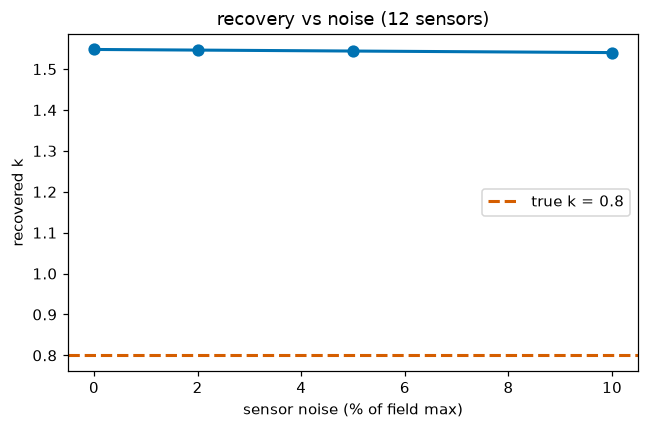

In [28]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([f * 100 for f in noise_fracs], noise_results,
        "o-", color=OKABE[0], lw=2, ms=7)
ax.axhline(k_true, color=OKABE[3], ls="--", lw=2, label=f"true k = {k_true}")

ax.set_xlabel("sensor noise (% of field max)")
ax.set_ylabel("recovered k")
ax.set_title("recovery vs noise (12 sensors)")
ax.legend(); plt.tight_layout(); plt.show()

Recovery holds while noise is small, then bends away as it grows. Two levers push that threshold out: **more sensors** (noise averages down) and a **stronger data weight** via `compile(..., loss_weights=...)`.

### Takeaways — Example 1

- The inverse recipe is **one change** from the forward one: make the unknown a `dde.Variable`, add the sensor data as a `PointSetBC`, and pass the variable to `compile(external_trainable_variables=[...])`.
- The physics regularises the fit, so recovery survives modest noise and imperfect placement.
- Placement and noise still set the accuracy — treat them as design choices, not afterthoughts.

## Example 2 — Recover a viscosity from a velocity profile

A fluid case, kept 1-D so it trains in seconds and the identifiability story stays clean.

Fully-developed flow between two plates, driven by a pressure gradient:

$$\mu\,u'' = \frac{dp}{dx}, \qquad u = 0 \text{ at the walls.}$$

In [29]:
# Channel half-height, pressure gradient, and the true viscosity.
H, dpdx, mu_true = 1.0, -1.0, 0.02
geom1d = dde.geometry.Interval(-H, H)


# Analytical (Poiseuille) profile, for reference and for making the data.
def u_exact(y, mu=mu_true, dp=dpdx):
    return (-dp) / (2 * mu) * (H**2 - y**2)

In [30]:
# Sparse velocity sensors across the channel, with a little noise.
rv = np.random.default_rng(7)
Nv = 10

vy = np.sort(rv.uniform(-0.9 * H, 0.9 * H, Nv)).reshape(-1, 1)
vu = u_exact(vy) + 0.2 * rv.standard_normal((Nv, 1))   # ~1% of u_max

for i in range(Nv):
    print(f"  y = {vy[i, 0]:+.2f}   u = {vu[i, 0]:.2f}")

  y = -0.89   u = 5.27
  y = -0.49   u = 18.95
  y = -0.36   u = 21.79
  y = -0.06   u = 24.73
  y = +0.23   u = 23.73
  y = +0.50   u = 18.98
  y = +0.53   u = 17.58
  y = +0.58   u = 16.55
  y = +0.67   u = 13.32
  y = +0.71   u = 11.96


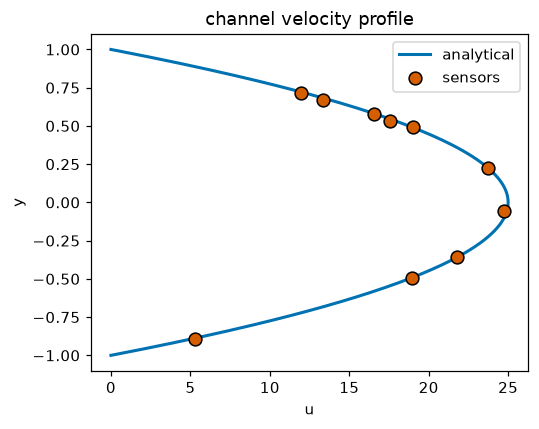

In [31]:
yy = np.linspace(-H, H, 200).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(u_exact(yy), yy, color=OKABE[0], lw=2, label="analytical")
ax.scatter(vu, vy, color=OKABE[3], edgecolors="black", s=70, zorder=5, label="sensors")

ax.set_xlabel("u"); ax.set_ylabel("y")
ax.set_title("channel velocity profile")
ax.legend(); plt.tight_layout(); plt.show()

In [32]:
# Reusable inverse solve for viscosity, given the pressure gradient we assume
# in the PDE (dp_used). Same structure as inverse_k.
def inverse_mu(dp_used, vy, vu, mu_init=0.05, adam_iters=2500, seed=0):
    dde.config.set_random_seed(seed)
    mu_var = dde.Variable(mu_init)

    # 1D momentum balance: mu * u'' = dp/dx.
    def pde(y, u):
        u_yy = dde.grad.hessian(u, y, i=0, j=0)
        return mu_var * u_yy - dp_used

    # No-slip walls, plus the velocity measurements.
    bc  = dde.icbc.DirichletBC(geom1d, lambda y: 0.0, lambda y, on: on)
    obs = dde.icbc.PointSetBC(vy, vu, component=0)

    data = dde.data.PDE(geom1d, pde, [bc, obs],
                        num_domain=200, num_boundary=2, anchors=vy)
    net   = dde.nn.FNN([1, 20, 20, 1], "tanh", "Glorot uniform")
    model = dde.Model(data, net)

    track = TrackVar(mu_var)
    model.compile("adam", lr=1e-3, external_trainable_variables=[mu_var])
    model.train(iterations=adam_iters, display_every=1000000, callbacks=[track])

    model.compile("L-BFGS", external_trainable_variables=[mu_var])
    model.train(display_every=1000000)
    return read_var(mu_var), track.history, model

In [33]:
# Recover viscosity using the correct pressure gradient.
mu_rec, mu_hist, model_mu = inverse_mu(dpdx, vy, vu)

print("=" * 40)
print(f"  true mu      : {mu_true:.4f}")
print(f"  recovered mu : {mu_rec:.4f}   (err {abs(mu_rec - mu_true) / mu_true * 100:.1f}%)")
print("=" * 40)

Compiling model...
'compile' took 0.000134 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [1.00e+00, 1.76e-02, 3.29e+02]    [1.00e+00, 1.76e-02, 3.29e+02]    []  


2500      [9.97e-01, 1.45e+00, 2.95e+00]    [9.97e-01, 1.45e+00, 2.95e+00]    []  



Best model at step 2500:
  train loss: 5.39e+00
  test loss: 5.39e+00
  test metric: []

'train' took 2.388796 s



...

Training model...

Step      Train loss                        Test loss                         Test metric


2500      [9.97e-01, 1.45e+00, 2.95e+00]    [9.97e-01, 1.45e+00, 2.95e+00]    []  


2814      [3.79e-03, 9.17e-05, 1.18e-02]    [3.79e-03, 9.17e-05, 1.18e-02]    []  



Best model at step 2814:
  train loss: 1.57e-02
  test loss: 1.57e-02
  test metric: []

'train' took 0.685157 s



  true mu      : 0.0200
  recovered mu : 0.0201   (err 0.4%)


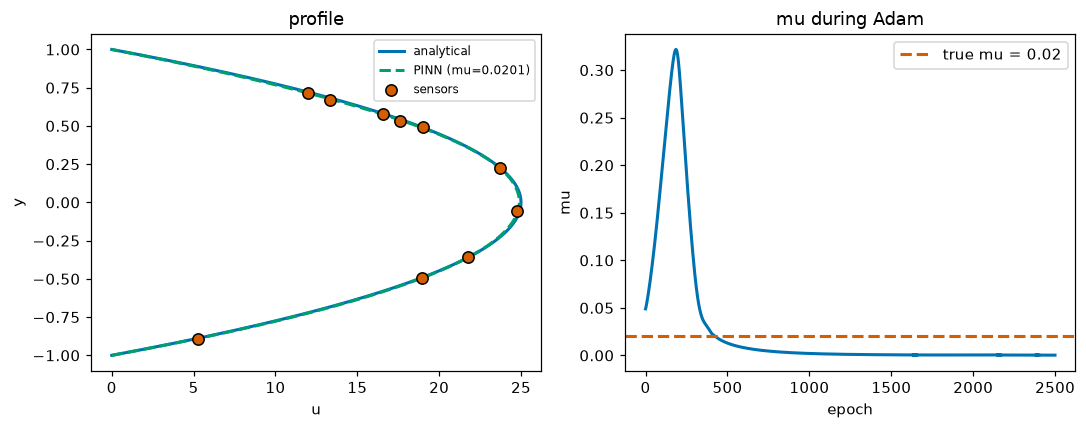

In [34]:
u_fit = model_mu.predict(yy).ravel()

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# Left: fitted profile vs analytical, with the sensor data.
axs[0].plot(u_exact(yy), yy, color=OKABE[0], lw=2, label="analytical")
axs[0].plot(u_fit, yy, ls="--", color=OKABE[2], lw=2, label=f"PINN (mu={mu_rec:.4f})")
axs[0].scatter(vu, vy, color=OKABE[3], edgecolors="black", s=55, zorder=5, label="sensors")
axs[0].set_xlabel("u"); axs[0].set_ylabel("y"); axs[0].set_title("profile")
axs[0].legend(fontsize=8)

# Right: viscosity converging during Adam.
axs[1].plot(mu_hist, color=OKABE[0], lw=2)
axs[1].axhline(mu_true, color=OKABE[3], ls="--", lw=2, label=f"true mu = {mu_true}")
axs[1].set_xlabel("epoch"); axs[1].set_ylabel("mu"); axs[1].set_title("mu during Adam")
axs[1].legend()
plt.tight_layout(); plt.show()

### A warning built into this problem

The profile depends on $\mu$ and $dp/dx$ **only through the ratio** $\dfrac{-dp/dx}{\mu}$. So the velocity data can pin that ratio, but not $\mu$ on its own. Let's prove it.

In [35]:
# Now lie to the solver: tell it dp/dx = -2 instead of -1.
mu_wrong, _, _ = inverse_mu(2 * dpdx, vy, vu)

print(f"correct dp/dx = {dpdx}   -> mu = {mu_rec:.4f}")
print(f"wrong   dp/dx = {2 * dpdx} -> mu = {mu_wrong:.4f}   (about {mu_wrong / mu_rec:.1f}x)")
print(f"ratio (-dp/dx)/mu:  correct = {(-dpdx) / mu_rec:.2f}   wrong = {(-2 * dpdx) / mu_wrong:.2f}")

Compiling model...
'compile' took 0.000150 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [4.00e+00, 1.76e-02, 3.29e+02]    [4.00e+00, 1.76e-02, 3.29e+02]    []  


2500      [3.99e+00, 1.44e+00, 2.94e+00]    [3.99e+00, 1.44e+00, 2.94e+00]    []  



Best model at step 2500:
  train loss: 8.37e+00
  test loss: 8.37e+00
  test metric: []

'train' took 2.481294 s



...

Training model...

Step      Train loss                        Test loss                         Test metric


2500      [3.99e+00, 1.44e+00, 2.94e+00]    [3.99e+00, 1.44e+00, 2.94e+00]    []  


2857      [2.84e-03, 2.98e-04, 1.72e-02]    [2.84e-03, 2.98e-04, 1.72e-02]    []  



Best model at step 2857:
  train loss: 2.03e-02
  test loss: 2.03e-02
  test metric: []

'train' took 0.791231 s



correct dp/dx = -1.0   -> mu = 0.0201
wrong   dp/dx = -2.0 -> mu = 0.0402   (about 2.0x)
ratio (-dp/dx)/mu:  correct = 49.82   wrong = 49.74


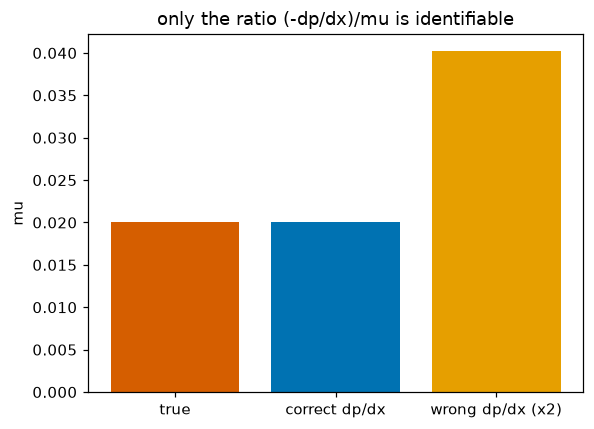

In [36]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.bar(["true", "correct dp/dx", "wrong dp/dx (x2)"],
       [mu_true, mu_rec, mu_wrong],
       color=[OKABE[3], OKABE[0], OKABE[1]])

ax.set_ylabel("mu")
ax.set_title("only the ratio (-dp/dx)/mu is identifiable")
plt.tight_layout(); plt.show()

The recovered viscosity doubles, yet the ratio that sets the velocity is unchanged. Nothing broke in the optimiser — the data simply does not contain $\mu$ alone. To pin the viscosity you must also know $dp/dx$ (or measure a shear stress).

# When inverse problems fail

The viscosity case already showed one failure mode. Here is the sharpest one, made concrete.

**A parameter you cannot see.** Back to conduction, but with **no source** ($Q=0$) and boundary condition $T = x$. The solution is then independent of $k$, so the data holds no information about it.

In [37]:
# Reference run: with a source (Q=1), k IS identifiable. Adam only.
_, hist_ok, _ = inverse_k(obs_xy, obs_T, Q=1.0, bc_value=0.0,
                          k_init=1.5, adam_iters=3000, use_lbfgs=False)

Compiling model...
'compile' took 0.000155 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.84e-01, 1.89e-02, 2.92e-03]    [8.84e-01, 1.89e-02, 2.92e-03]    []  


3000      [2.89e-05, 2.73e-04, 2.08e-04]    [2.89e-05, 2.73e-04, 2.08e-04]    []  



Best model at step 3000:
  train loss: 5.10e-04
  test loss: 5.10e-04
  test metric: []

'train' took 6.299744 s



In [38]:
# The unidentifiable twin: no source (Q=0) and boundary condition T = x.
# With Q=0 the equation is lap(T)=0, and k multiplies zero, so the data
# carries no information about k.
def inverse_k_harmonic(obs_xy, obs_T, k_init=1.5, adam_iters=3000, seed=0):
    dde.config.set_random_seed(seed)
    k_var = dde.Variable(k_init)

    def pde(x, T):
        T_xx = dde.grad.hessian(T, x, i=0, j=0)
        T_yy = dde.grad.hessian(T, x, i=1, j=1)
        return -k_var * (T_xx + T_yy)

    # Boundary condition T = x (the x-coordinate of each boundary point).
    bc  = dde.icbc.DirichletBC(geom, lambda x: x[:, 0:1], lambda x, on: on)
    obs = dde.icbc.PointSetBC(obs_xy, obs_T, component=0)

    data = dde.data.PDE(geom, pde, [bc, obs],
                        num_domain=500, num_boundary=100, anchors=obs_xy)
    net   = dde.nn.FNN([2, 32, 32, 32, 1], "tanh", "Glorot uniform")
    model = dde.Model(data, net)

    track = TrackVar(k_var)
    model.compile("adam", lr=1e-3, external_trainable_variables=[k_var])
    model.train(iterations=adam_iters, display_every=1000000, callbacks=[track])
    return read_var(k_var), track.history, model

In [39]:
# Feed it data consistent with T = x (we reuse the sensor x-coordinates).
k_bad, hist_bad, model_bad = inverse_k_harmonic(obs_xy, sx.reshape(-1, 1))

# The data fit is near-perfect even though k never moved from its guess.
data_fit = np.abs(model_bad.predict(obs_xy).ravel() - sx).max()

print(f"harmonic case: max data residual = {data_fit:.2e}")
print(f"k stayed near its initial guess: k = {k_bad:.3f} (started at 1.5)")

Compiling model...
'compile' took 0.000162 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [7.88e-03, 3.80e-01, 2.56e-01]    [7.88e-03, 3.80e-01, 2.56e-01]    []  


3000      [2.38e-05, 5.13e-05, 4.60e-05]    [2.38e-05, 5.13e-05, 4.60e-05]    []  



Best model at step 3000:
  train loss: 1.21e-04
  test loss: 1.21e-04
  test metric: []

'train' took 6.046842 s



harmonic case: max data residual = 9.39e-03
k stayed near its initial guess: k = 1.434 (started at 1.5)


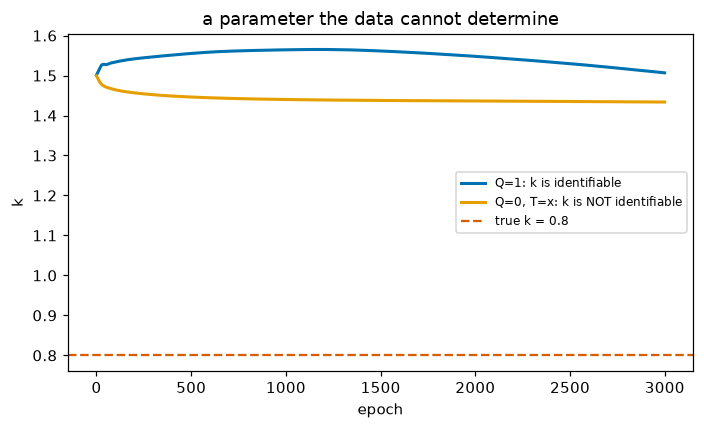

In [40]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(hist_ok,  color=OKABE[0], lw=2, label="Q=1: k is identifiable")
ax.plot(hist_bad, color=OKABE[1], lw=2, label="Q=0, T=x: k is NOT identifiable")
ax.axhline(k_true, color=OKABE[3], ls="--", lw=1.5, label=f"true k = {k_true}")

ax.set_xlabel("epoch"); ax.set_ylabel("k")
ax.set_title("a parameter the data cannot determine")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### A short field guide to failure

Inverse problems go wrong for **physical**, not numerical, reasons. Check these before trusting a recovered number:

- **No sensitivity** — the measurement barely changes when the parameter changes.
- **Only a combination is identifiable** — like $(-dp/dx)/\mu$ above.
- **Bad placement** — sensors where the field is flat.
- **Too much noise** — it drowns the signal the parameter leaves in the data.

A perfect data fit does **not** guarantee a trustworthy parameter.

# Part C — A solidification front *(optional stretch)*

Heavier physics, and the last cell is the one temperamental piece in the notebook, so it is walled off here. Skip it if time is short.

A cold wall freezes a liquid; the solid-liquid front advances into the domain. This is the classic **Stefan problem**.

### The exact solution (Neumann)

This problem has a similarity solution. The front advances as the square root of time,

$$s(t) = 2\lambda\sqrt{\alpha t},$$

and the temperature in the solid follows an error function. The constant $\lambda$ comes from a small transcendental equation.

In [41]:
from scipy.special import erf
from scipy.optimize import brentq

# Material and boundary setup for one-phase solidification.
alpha, Tm, Tw = 1.0, 0.0, -1.0
St = 0.5                 # Stefan number
L  = 1.0 / St            # latent heat (with c=1 and Tm-Tw=1)

# Solve the transcendental equation for the similarity constant lambda.
lam = brentq(lambda l: l * np.exp(l * l) * erf(l) - St / np.sqrt(np.pi), 1e-6, 5.0)
print(f"Stefan number St = {St}, latent heat L = {L}, lambda = {lam:.4f}")


# Exact front position and solid temperature profile.
def s_exact(t):     return 2 * lam * np.sqrt(alpha * t)
def T_exact(x, t):  return Tw + (Tm - Tw) * erf(x / (2 * np.sqrt(alpha * t))) / erf(lam)

Stefan number St = 0.5, latent heat L = 2.0, lambda = 0.4648


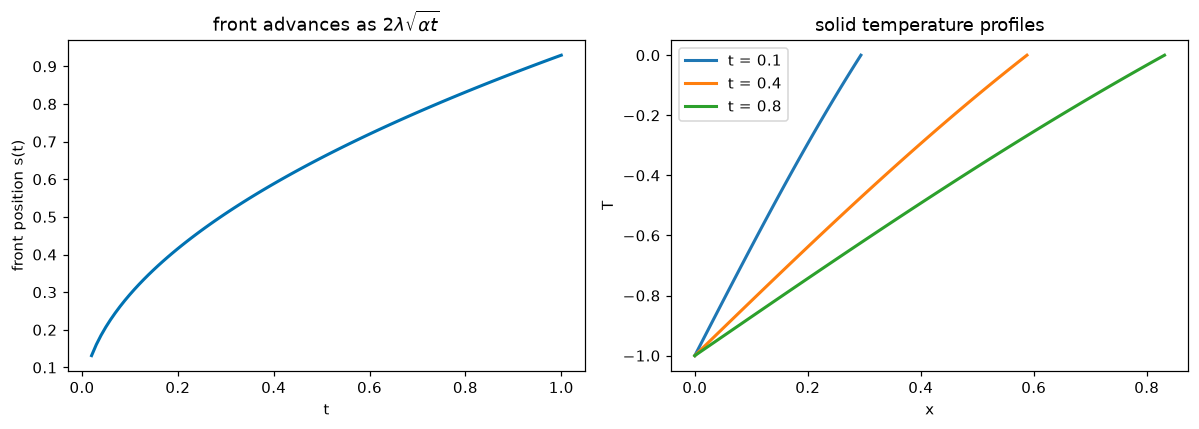

In [42]:
tt = np.linspace(0.02, 1.0, 100)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

# Left: the front advances like sqrt(t).
axs[0].plot(tt, s_exact(tt), color=OKABE[0], lw=2)
axs[0].set_xlabel("t"); axs[0].set_ylabel("front position s(t)")
axs[0].set_title(r"front advances as $2\lambda\sqrt{\alpha t}$")

# Right: solid temperature profiles at a few times.
for t in [0.1, 0.4, 0.8]:
    xg = np.linspace(0, s_exact(t), 100)
    axs[1].plot(xg, T_exact(xg, t), lw=2, label=f"t = {t}")
axs[1].set_xlabel("x"); axs[1].set_ylabel("T")
axs[1].set_title("solid temperature profiles")
axs[1].legend()
plt.tight_layout(); plt.show()

### A finite-difference check (enthalpy method)

Before trusting anything, solve the same problem with a classic scheme and confirm it lands on the Neumann front. The trick for phase change: track **enthalpy** instead of temperature, so the latent-heat jump is handled automatically.

In [43]:
# Explicit enthalpy method for one-phase solidification. We march the enthalpy
# h in time, then recover temperature T and liquid fraction phi from it.
def enthalpy_solve(L, alpha=1.0, Xmax=3.0, nx=301, tend=1.0,
                   checkpoints=(0.25, 0.5, 1.0)):
    dx = Xmax / (nx - 1)
    x  = np.linspace(0, Xmax, nx)
    dt = 0.2 * dx * dx / alpha          # stable explicit time step

    # Recover T and phi from enthalpy h.
    def recover(h):
        Tn  = np.where(h <= 0, h, np.where(h >= L, h - L, 0.0))
        phn = np.where(h <= 0, 0.0, np.where(h >= L, 1.0, h / L))
        return Tn, phn

    # Start: everything liquid at the melt temperature.
    T   = np.zeros(nx)
    phi = np.ones(nx)
    h   = T + L * phi

    snap = {}
    t  = 0.0
    nt = int(round(tend / dt)) + 1

    for n in range(nt):
        # Diffusion of the interior points (explicit Laplacian).
        lap = np.zeros(nx)
        lap[1:-1] = (T[2:] - 2 * T[1:-1] + T[:-2]) / dx**2
        h[1:-1] += dt * alpha * lap[1:-1]

        # Boundary conditions: cold solid wall, liquid far field.
        h[0]  = Tw
        h[-1] = 0.0 + L * 1.0

        T, phi = recover(h)
        t += dt

        # Save snapshots at the requested times.
        for cp in checkpoints:
            if cp not in snap and t >= cp - 1e-12:
                snap[cp] = (x.copy(), T.copy(), phi.copy(), dx)
    return snap

In [44]:
snap = enthalpy_solve(L)

# Compare the numerical front position to the exact one.
print("front position: exact vs enthalpy FDM")
for cp in [0.25, 0.5, 1.0]:
    x, Tn, phin, dx = snap[cp]
    s_num = dx * np.sum(1.0 - phin)          # total solidified length
    print(f"  t={cp}:  s_exact={s_exact(cp):.4f}   s_fdm={s_num:.4f}")

front position: exact vs enthalpy FDM
  t=0.25:  s_exact=0.4648   s_fdm=0.4700
  t=0.5:  s_exact=0.6573   s_fdm=0.6622
  t=1.0:  s_exact=0.9296   s_fdm=0.9345


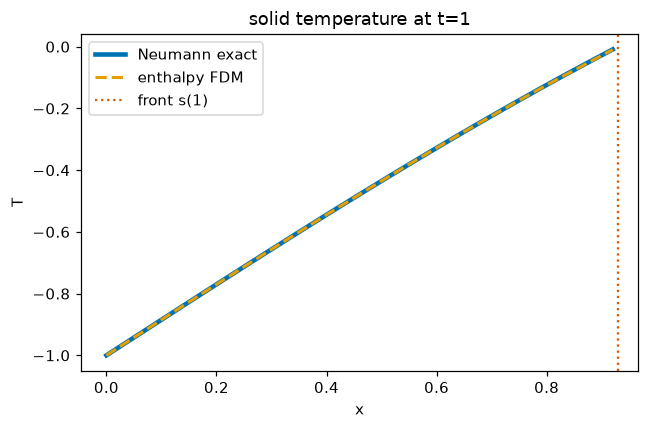

In [45]:
x, Tn, phin, dx = snap[1.0]
mask = x <= s_exact(1.0)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x[mask], T_exact(x[mask], 1.0), color=OKABE[0], lw=3, label="Neumann exact")
ax.plot(x[mask], Tn[mask], ls="--", color=OKABE[1], lw=2, label="enthalpy FDM")
ax.axvline(s_exact(1.0), color=OKABE[3], ls=":", label="front s(1)")

ax.set_xlabel("x"); ax.set_ylabel("T")
ax.set_title("solid temperature at t=1")
ax.legend(); plt.tight_layout(); plt.show()

### The PINN version (demonstration)

A moving boundary is awkward for a PINN because the domain $0 < x < s(t)$ changes shape. The standard fix is a **change of coordinates** $\xi = x/s(t)$, which freezes the front at $\xi = 1$. We then recover the front coefficient $\beta = 2\lambda$.

In [46]:
# Unknown to recover: the front coefficient beta. We solve on the fixed
# domain xi = x/s(t) in [0,1], so the moving front becomes a fixed boundary.
beta_exact = 2 * lam
beta = dde.Variable(0.5)
geom_xi = dde.geometry.Interval(0, 1)

In [47]:
# The similarity ODE in xi. jacobian = first derivative, hessian = second.
def stefan_ode(xi, T):
    T_x  = dde.grad.jacobian(T, xi, i=0, j=0)
    T_xx = dde.grad.hessian(T, xi, i=0, j=0)
    return T_xx + (beta**2 * xi / 2.0) * T_x

In [48]:
# Helpers to pick out the two ends of the interval.
def at0(x, on): return on and np.isclose(x[0], 0)
def at1(x, on): return on and np.isclose(x[0], 1)

# Wall temperature at xi=0, melt temperature at the front xi=1.
bc_wall  = dde.icbc.DirichletBC(geom_xi, lambda x: Tw, at0)
bc_front = dde.icbc.DirichletBC(geom_xi, lambda x: Tm, at1)


# Stefan condition at the front, written as a derivative constraint.
def stefan_bc(x, T, X):
    T_x = dde.grad.jacobian(T, x, i=0, j=0)
    return T_x - L * beta**2 / 2.0

bc_stefan = dde.icbc.OperatorBC(geom_xi, stefan_bc, at1)

In [49]:
# Assemble and train. This is the most delicate solve in the notebook.
data_s = dde.data.PDE(geom_xi, stefan_ode,
                      [bc_wall, bc_front, bc_stefan],
                      num_domain=64, num_boundary=2)
net_s   = dde.nn.FNN([1, 24, 24, 1], "tanh", "Glorot uniform")
model_s = dde.Model(data_s, net_s)

model_s.compile("adam", lr=5e-3, external_trainable_variables=[beta])
model_s.train(iterations=6000, display_every=1000000)
model_s.compile("L-BFGS", external_trainable_variables=[beta])
model_s.train(display_every=1000000)

beta_rec = read_var(beta)
print(f"beta exact (2*lambda)  = {beta_exact:.4f}")
print(f"beta recovered by PINN = {beta_rec:.4f}   (err {abs(beta_rec - beta_exact) / beta_exact * 100:.1f}%)")

Compiling model...
'compile' took 0.000123 s



Training model...

Step      Train loss                                  Test loss                                   Test metric


0         [9.90e-04, 1.00e+00, 1.46e-01, 3.58e-01]    [9.90e-04, 1.00e+00, 1.46e-01, 3.58e-01]    []  


6000      [4.39e-06, 3.14e-07, 1.20e-06, 2.91e-07]    [4.39e-06, 3.14e-07, 1.20e-06, 2.91e-07]    []  



Best model at step 6000:
  train loss: 6.19e-06
  test loss: 6.19e-06
  test metric: []

'train' took 4.967039 s



...

Training model...

Step      Train loss                                  Test loss                                   Test metric


6000      [4.39e-06, 3.14e-07, 1.20e-06, 2.91e-07]    [4.39e-06, 3.14e-07, 1.20e-06, 2.91e-07]    []  


6087      [2.71e-09, 3.55e-15, 1.42e-14, 5.68e-14]    [2.71e-09, 3.55e-15, 1.42e-14, 5.68e-14]    []  



Best model at step 6087:
  train loss: 2.71e-09
  test loss: 2.71e-09
  test metric: []

'train' took 0.148775 s



beta exact (2*lambda)  = 0.9296
beta recovered by PINN = 0.9296   (err 0.0%)


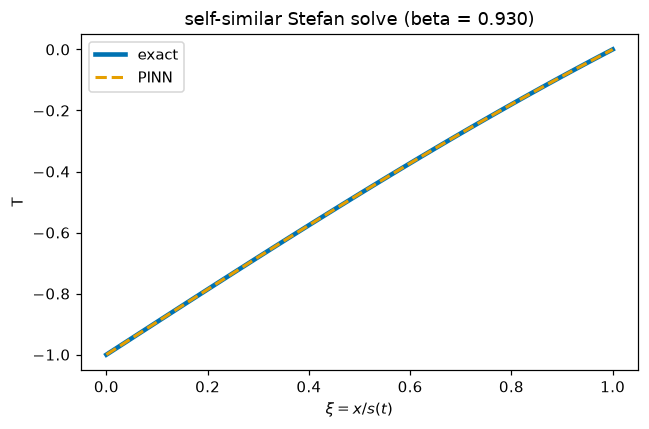

In [50]:
xi = np.linspace(0, 1, 100).reshape(-1, 1)
T_pinn_xi = model_s.predict(xi).ravel()
T_true_xi = Tw + (Tm - Tw) * erf(xi.ravel() * beta_exact / 2) / erf(lam)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(xi.ravel(), T_true_xi, color=OKABE[0], lw=3, label="exact")
ax.plot(xi.ravel(), T_pinn_xi, ls="--", color=OKABE[1], lw=2, label="PINN")

ax.set_xlabel(r"$\xi = x/s(t)$"); ax.set_ylabel("T")
ax.set_title(f"self-similar Stefan solve (beta = {beta_rec:.3f})")
ax.legend(); plt.tight_layout(); plt.show()

# Takeaways

- **The inverse move is tiny.** Turn the unknown into a `dde.Variable`, add the measurements as a `PointSetBC`, and pass the variable to `compile(external_trainable_variables=[...])`.
- **The physics regularises.** Sparse, noisy data still gives a usable parameter because the PDE constrains the field.
- **Identifiability comes first.** If the data is insensitive to the parameter, or only a combination is observable, no optimiser will save you.
- **Always keep a baseline.** A finite-difference or analytical reference is what tells you whether the PINN answer can be trusted.

# Training animation — the DeepXDE PINN learning the temperature field
The notebook sets no experiment, so I added this animation and the seed repeats below. The callback on the Adam stage of Part A's forward PINN (`FNN([2, 32, 32, 32, 1], "tanh", "Glorot uniform")`, Adam 1e-3 for 3,000 iterations, then L-BFGS) stored the field on the 61×61 reference grid and its error every 50 iterations, so the animation comes from the same run; the last frame is the final model after L-BFGS. Video: `../animations/02_training_dashboard.mp4`; last frame: `../animations/02_final_frame.png`.

In [51]:
import pickle
from pathlib import Path
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = ANIM_DIR; anim_dir.mkdir(exist_ok=True)
ANIM_CB.model = model_fwd; ANIM_CB.snap(label=3000 + 1)   # the final model, after the L-BFGS polish (plotted at the right edge)
snaps = ANIM_CB.snaps; snaps[-1]["after_lbfgs"] = True; pickle.dump(snaps, open(anim_dir / f"{ANIM_PREFIX}snapshots.pkl", "wb"))
anim_loss = np.array(model_fwd.losshistory.loss_train).sum(axis=1); anim_steps = np.array(model_fwd.losshistory.steps)
anim_loss, anim_steps = anim_loss[anim_steps <= 3000], anim_steps[anim_steps <= 3000]
print(f"Forward PINN: RMSE vs FD reference {snaps[-2]['err']:.2e} after 3000 Adam iterations, {snaps[-1]['err']:.2e} after L-BFGS")

Forward PINN: RMSE vs FD reference 1.15e-02 after 3000 Adam iterations, 1.75e-03 after L-BFGS


In [52]:
vmx = T_ref.max(); emax = np.abs(snaps[min(4, len(snaps) - 1)]["T"] - T_ref).max()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
def anim_draw(k):
    s_ = snaps[k]
    for a in axes: a.clear()
    axes[0].contourf(XX, YY, T_ref, levels=np.linspace(0, vmx, 31), cmap=CMAP_T); axes[0].set_title(f"FD reference (k={k_true})")
    axes[1].contourf(XX, YY, np.clip(s_["T"], 0, vmx), levels=np.linspace(0, vmx, 31), cmap=CMAP_T); axes[1].set_title("PINN, after L-BFGS (final)" if s_.get("after_lbfgs") else f"PINN, Adam iteration {s_['it']}")
    axes[2].contourf(XX, YY, np.abs(s_["T"] - T_ref), levels=np.linspace(0, emax, 31), cmap=CMAP_ERR, extend="max"); axes[2].set_title("|error|")
    for a in axes[:3]: a.set_aspect("equal"); a.set_xlabel("x"); a.set_ylabel("y")
    sel = anim_steps <= s_["it"]
    axes[3].semilogy(anim_steps[sel], anim_loss[sel], "o-", ms=3, label="training loss (PDE + BC)")
    axes[3].semilogy([x["it"] for x in snaps[:k + 1]], [x["err"] for x in snaps[:k + 1]], label="RMSE vs FD")
    axes[3].set_xlim(0, 3050); axes[3].set_ylim(min(anim_loss.min(), min(x["err"] for x in snaps)) * 0.5, max(anim_loss.max(), snaps[0]["err"]) * 2); axes[3].legend(); axes[3].set_xlabel("iteration")
    fig.suptitle("Stage 2 — DeepXDE PINN for -k ∇²T = Q: training run"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(anim_dir / f"{ANIM_PREFIX}final_frame.png", dpi=100)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / f"{ANIM_PREFIX}training_dashboard.mp4", writer=FFMpegWriter(fps=10, bitrate=1600), dpi=90)
plt.close(fig); print(f"Animation: {len(snaps)} frames written")

Animation: 62 frames written


**What the animation shows.** The finite-difference reference temperature, the PINN's field as Adam trains, the absolute error, and the training loss with the error against the reference.

# Three seeds
I repeat every result that depends on a random initialisation (the sampled points, the network weights, the path of the unknown during training) with the seeds 0, 1 and 2; seed 0 is the setting of the cells above. That covers the forward PINN, the inverse conductivity with the full recipe (Adam then L-BFGS), the placement and noise studies (Adam only, as above), the viscosity with the correct and the wrong pressure gradient, the unidentifiable harmonic case and the Stefan front coefficient. Each row is one training run; the summary gives the mean and the standard deviation over the three seeds. Tables and figure: `../results/02_deepxde_forward_and_inverse/exercises/`; forward models: `../models/02_deepxde_forward_and_inverse/`.

In [53]:
import pandas as pd, time
from pathlib import Path
ex_dir = EXERCISES_DIR; ex_dir.mkdir(exist_ok=True); MODELS = MODELS_DIR; MODELS.mkdir(exist_ok=True)
SEEDS = (0, 1, 2)
rows_f = []
for s in SEEDS:
    dde.config.set_random_seed(s)
    d_ = dde.data.PDE(geom, heat_forward, [bc], num_domain=600, num_boundary=120, num_test=400)
    m_ = dde.Model(d_, dde.nn.FNN([2, 32, 32, 32, 1], "tanh", "Glorot uniform"))
    t0 = time.time(); m_.compile("adam", lr=1e-3); m_.train(iterations=3000, display_every=100000); t_adam = time.time() - t0
    T_a = m_.predict(xy).reshape(n_ref, n_ref); e_a = np.abs(T_a - T_ref)
    m_.compile("L-BFGS"); m_.train(display_every=100000); tt = time.time() - t0
    T_ = m_.predict(xy).reshape(n_ref, n_ref); e = np.abs(T_ - T_ref); m_.save(str(MODELS / f"pinn_forward_seed{s}"))
    rows_f.append(dict(case="forward PINN", seed=s, max_err_after_adam=float(e_a.max()), max_err=float(e.max()), mean_err=float(e.mean()), rmse=float(np.sqrt((e**2).mean())), lbfgs_steps=int(m_.train_state.step) - 3000, adam_s=round(t_adam, 1), train_s=round(tt, 1)))
    print(f"seed {s}: max error {e.max():.5f}, mean {e.mean():.5f}")
seeds_f = pd.DataFrame(rows_f); seeds_f.to_csv(ex_dir / "seeds_forward_runs.csv", index=False); print(seeds_f.round(5).to_string())

Compiling model...
'compile' took 0.000179 s



Training model...

Step      Train loss              Test loss               Test metric


0         [9.36e-01, 1.87e-02]    [9.37e-01, 1.87e-02]    []  


3000      [2.46e-05, 3.99e-04]    [1.63e-05, 3.99e-04]    []  



Best model at step 3000:
  train loss: 4.23e-04
  test loss: 4.15e-04
  test metric: []

'train' took 6.409657 s



...

Training model...

Step      Train loss              Test loss               Test metric


3000      [1.53e-05, 4.29e-04]    [1.10e-05, 4.29e-04]    []  


3003      [1.53e-05, 4.29e-04]    [1.11e-05, 4.29e-04]    []  



Best model at step 3003:
  train loss: 4.44e-04
  test loss: 4.40e-04
  test metric: []

'train' took 0.040784 s



seed 2: max error 0.05995, mean 0.01058
           case  seed  max_err_after_adam  max_err  mean_err     rmse  lbfgs_steps  adam_s  train_s
0  forward PINN     0             0.05589  0.01093   0.00136  0.00175         1000     6.4     10.3
1  forward PINN     1             0.05573  0.01037   0.00064  0.00098         1000     6.5     10.2
2  forward PINN     2             0.06012  0.05995   0.01058  0.01259            3     6.3      6.3


## The inverse conductivity: the 12-sensor layout, placement and noise, three seeds each

In [54]:
rows_k = []
for s in SEEDS:
    kk, hist_, _ = inverse_k(obs_xy, obs_T, seed=s)
    rows_k.append(dict(study="12 sensors, Adam 3000 + L-BFGS", setting="12 random interior sensors", seed=s, k=kk, k_after_adam=hist_[-1], rel_err_pct=abs(kk - k_true) / k_true * 100))
    for name, pts in layouts.items():
        oT = sample_field(T_ref, pts[:, 0], pts[:, 1]).reshape(-1, 1); kk, hist_, _ = inverse_k(pts, oT, adam_iters=2000, use_lbfgs=False, seed=s)
        rows_k.append(dict(study="placement, Adam 2000 only", setting=name, seed=s, k=kk, k_after_adam=kk, rel_err_pct=abs(kk - k_true) / k_true * 100))
    for f in noise_fracs:
        ng = np.random.default_rng(100); noise = f * Tmax * ng.standard_normal((N_sensors, 1)); oT = sample_field(T_ref, sx, sy).reshape(-1, 1) + noise
        kk, hist_, _ = inverse_k(obs_xy, oT, adam_iters=2000, use_lbfgs=False, seed=s)
        rows_k.append(dict(study="noise, Adam 2000 only", setting=f"{f*100:.0f} % of Tmax", seed=s, k=kk, k_after_adam=kk, rel_err_pct=abs(kk - k_true) / k_true * 100))
    print(f"seed {s} done")
seeds_k = pd.DataFrame(rows_k); seeds_k.to_csv(ex_dir / "seeds_inverse_k_runs.csv", index=False); print(seeds_k.round(4).to_string())

Compiling model...
'compile' took 0.000131 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.84e-01, 1.89e-02, 2.92e-03]    [8.84e-01, 1.89e-02, 2.92e-03]    []  


3000      [2.89e-05, 2.73e-04, 2.08e-04]    [2.89e-05, 2.73e-04, 2.08e-04]    []  



Best model at step 3000:
  train loss: 5.10e-04
  test loss: 5.10e-04
  test metric: []

'train' took 6.325402 s



...

Training model...

Step      Train loss                        Test loss                         Test metric


0         [8.74e-01, 7.17e-03, 1.28e-03]    [8.74e-01, 7.17e-03, 1.28e-03]    []  


2000      [2.82e-05, 3.49e-04, 3.75e-04]    [2.82e-05, 3.49e-04, 3.75e-04]    []  



Best model at step 2000:
  train loss: 7.52e-04
  test loss: 7.52e-04
  test metric: []

'train' took 4.202381 s



seed 2 done
                             study                     setting  seed       k  k_after_adam  rel_err_pct
0   12 sensors, Adam 3000 + L-BFGS  12 random interior sensors     0  0.8466        1.5068       5.8230
1        placement, Adam 2000 only             spread interior     0  1.5379        1.5379      92.2348
2        placement, Adam 2000 only              near cold edge     0  1.5888        1.5888      98.5966
3        placement, Adam 2000 only                few, central     0  1.5107        1.5107      88.8432
4            noise, Adam 2000 only                 0 % of Tmax     0  1.5481        1.5481      93.5109
5            noise, Adam 2000 only                 2 % of Tmax     0  1.5466        1.5466      93.3189
6            noise, Adam 2000 only                 5 % of Tmax     0  1.5442        1.5442      93.0273
7            noise, Adam 2000 only                10 % of Tmax     0  1.5404        1.5404      92.5540
8   12 sensors, Adam 3000 + L-BFGS  12 random interi

## Viscosity, the unidentifiable case and the Stefan front, three seeds each

In [55]:
rows_m = []
for s in SEEDS:
    mu_r, _, _ = inverse_mu(dpdx, vy, vu, seed=s); mu_w, _, _ = inverse_mu(2 * dpdx, vy, vu, seed=s)
    k_h, _, m_h = inverse_k_harmonic(obs_xy, sx.reshape(-1, 1), seed=s); fit_h = float(np.abs(m_h.predict(obs_xy).ravel() - sx).max())
    dde.config.set_random_seed(s); beta_s = dde.Variable(0.5)
    def ode_s(xi, T):
        T_x = dde.grad.jacobian(T, xi, i=0, j=0); T_xx = dde.grad.hessian(T, xi, i=0, j=0)
        return T_xx + (beta_s**2 * xi / 2.0) * T_x
    def stefan_s(x, T, X): return dde.grad.jacobian(T, x, i=0, j=0) - L * beta_s**2 / 2.0
    d_ = dde.data.PDE(geom_xi, ode_s, [bc_wall, bc_front, dde.icbc.OperatorBC(geom_xi, stefan_s, at1)], num_domain=64, num_boundary=2)
    m_ = dde.Model(d_, dde.nn.FNN([1, 24, 24, 1], "tanh", "Glorot uniform"))
    m_.compile("adam", lr=5e-3, external_trainable_variables=[beta_s]); m_.train(iterations=6000, display_every=100000)
    m_.compile("L-BFGS", external_trainable_variables=[beta_s]); m_.train(display_every=100000); b_ = read_var(beta_s)
    rows_m.append(dict(seed=s, mu=mu_r, mu_rel_err_pct=abs(mu_r - mu_true) / mu_true * 100, mu_wrong_dpdx=mu_w, ratio_correct=(-dpdx) / mu_r, ratio_wrong=(-2 * dpdx) / mu_w,
                       k_harmonic=k_h, harmonic_data_residual=fit_h, beta=b_, beta_rel_err_pct=abs(b_ - beta_exact) / beta_exact * 100))
    print(f"seed {s}: mu {mu_r:.4f}, wrong-dp mu {mu_w:.4f}, harmonic k {k_h:.3f}, beta {b_:.4f}")
seeds_m = pd.DataFrame(rows_m); seeds_m.to_csv(ex_dir / "seeds_mu_harmonic_stefan_runs.csv", index=False); print(seeds_m.round(5).to_string())

Compiling model...
'compile' took 0.000122 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [1.00e+00, 1.76e-02, 3.29e+02]    [1.00e+00, 1.76e-02, 3.29e+02]    []  


2500      [9.97e-01, 1.45e+00, 2.95e+00]    [9.97e-01, 1.45e+00, 2.95e+00]    []  



Best model at step 2500:
  train loss: 5.39e+00
  test loss: 5.39e+00
  test metric: []

'train' took 2.516679 s



...

Training model...

Step      Train loss                                  Test loss                                   Test metric


6000      [2.53e-06, 1.23e-04, 1.16e-03, 4.06e-04]    [2.53e-06, 1.23e-04, 1.16e-03, 4.06e-04]    []  


6022      [2.60e-08, 1.42e-14, 2.72e-15, 3.55e-15]    [2.60e-08, 1.42e-14, 2.72e-15, 3.55e-15]    []  



Best model at step 6022:
  train loss: 2.60e-08
  test loss: 2.60e-08
  test metric: []

'train' took 0.035976 s



seed 2: mu 0.0201, wrong-dp mu 0.0402, harmonic k 1.424, beta 0.9296
   seed       mu  mu_rel_err_pct  mu_wrong_dpdx  ratio_correct  ratio_wrong  k_harmonic  harmonic_data_residual     beta  beta_rel_err_pct
0     0  0.02007         0.35682        0.04021       49.82223     49.74291     1.43372                 0.00939  0.92957           0.00009
1     1  0.02007         0.35441        0.04020       49.82342     49.75713     1.43542                 0.00185  0.92957           0.00055
2     2  0.02008         0.39093        0.04020       49.80530     49.75502     1.42435                 0.00142  0.92957           0.00013


## Summary over the three seeds

                                                           k_mean   k_std  k_after_adam_mean  k_after_adam_std  rel_err_pct_mean  rel_err_pct_std
study                          setting                                                                                                           
12 sensors, Adam 3000 + L-BFGS 12 random interior sensors  0.8391  0.0257             1.5154            0.0145            4.8846           3.2093
placement, Adam 2000 only      spread interior             1.5457  0.0132             1.5457            0.0132           93.2125           1.6522
                               near cold edge              1.5949  0.0095             1.5949            0.0095           99.3602           1.1881
                               few, central                1.5199  0.0153             1.5199            0.0153           89.9888           1.9121
noise, Adam 2000 only          0 % of Tmax                 1.5549  0.0113             1.5549            0.0113           94.

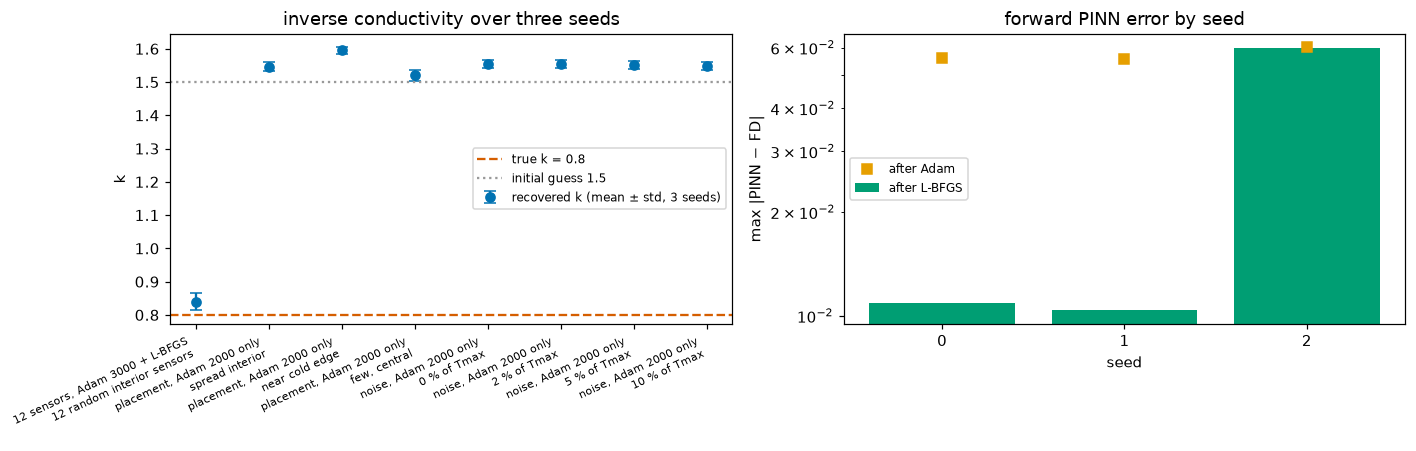

Result (three seeds): 12 sensors, Adam 3000 + L-BFGS / 12 random interior sensors: k = 0.839 ± 0.026; placement, Adam 2000 only / spread interior: k = 1.546 ± 0.013; placement, Adam 2000 only / near cold edge: k = 1.595 ± 0.010; placement, Adam 2000 only / few, central: k = 1.520 ± 0.015; noise, Adam 2000 only / 0 % of Tmax: k = 1.555 ± 0.011; noise, Adam 2000 only / 2 % of Tmax: k = 1.553 ± 0.011; noise, Adam 2000 only / 5 % of Tmax: k = 1.551 ± 0.012; noise, Adam 2000 only / 10 % of Tmax: k = 1.548 ± 0.012; forward max error 0.0271 ± 0.0285; mu 0.0201 ± 0.0000; beta 0.9296 ± 0.0000


In [56]:
sk = seeds_k.groupby(["study", "setting"], sort=False)[["k", "k_after_adam", "rel_err_pct"]].agg(["mean", "std"]); sk.columns = [f"{a}_{b}" for a, b in sk.columns]
sf = seeds_f[["max_err", "mean_err", "rmse", "max_err_after_adam", "train_s"]].agg(["mean", "std"]).T
sm = seeds_m.drop(columns="seed").agg(["mean", "std"]).T
pd.concat([sk.reset_index().assign(block="inverse k"), sf.reset_index().rename(columns={"index": "setting"}).assign(block="forward PINN"), sm.reset_index().rename(columns={"index": "setting"}).assign(block="mu, harmonic, Stefan")], ignore_index=True).to_csv(ex_dir / "seeds_summary.csv", index=False)
print(sk.round(4).to_string()); print(sf.round(5).to_string()); print(sm.round(5).to_string())
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
labels = [f"{a}\n{b}" for a, b in sk.index]; x_ = np.arange(len(sk))
axs[0].errorbar(x_, sk["k_mean"], yerr=sk["k_std"], fmt="o", color=OKABE[0], capsize=4, label="recovered k (mean ± std, 3 seeds)")
axs[0].axhline(k_true, color=OKABE[3], ls="--", label=f"true k = {k_true}"); axs[0].axhline(1.5, color="0.6", ls=":", label="initial guess 1.5")
axs[0].set_xticks(x_); axs[0].set_xticklabels(labels, fontsize=7, rotation=25, ha="right"); axs[0].set_ylabel("k"); axs[0].legend(fontsize=8); axs[0].set_title("inverse conductivity over three seeds")
axs[1].bar(seeds_f.seed, seeds_f.max_err, color=OKABE[2], label="after L-BFGS"); axs[1].plot(seeds_f.seed, seeds_f.max_err_after_adam, "s", color=OKABE[1], label="after Adam")
axs[1].set_xticks(list(seeds_f.seed)); axs[1].set_xlabel("seed"); axs[1].set_ylabel("max |PINN − FD|"); axs[1].set_yscale("log"); axs[1].legend(fontsize=8); axs[1].set_title("forward PINN error by seed")
plt.tight_layout(); plt.savefig(ex_dir / "seeds_summary.png", dpi=100); plt.show()
print("Result (three seeds): " + "; ".join(f"{i[0]} / {i[1]}: k = {r.k_mean:.3f} ± {r.k_std:.3f}" for i, r in sk.iterrows()) + f"; forward max error {sf.loc['max_err', 'mean']:.4f} ± {sf.loc['max_err', 'std']:.4f}; mu {sm.loc['mu', 'mean']:.4f} ± {sm.loc['mu', 'std']:.4f}; beta {sm.loc['beta', 'mean']:.4f} ± {sm.loc['beta', 'std']:.4f}")